# TUGAS KECERDASAN ARTIFISIAL UNTUK GEOFISIKA
## Perancangan Prompt AI dan Penyelesaian Masalah Geofisika
**Nama:** Elda Lorista Tammu

**NIM:** H061251008

**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika 
 
**Departemen:** Geofisika

### Daftar topik
1. Geostatistika: semivariogram dan interpolasi IDW
2. Seismologi: Diagram Wadati dan estimasi rasio \(V_p/V_s\)
3. Metode gravitasi: pemisahan anomali regional dan residual
4. Seismologi: estimasi magnitudo lokal dan atenuasi sederhana
5. Tektonofisika: estimasi regangan dari perpindahan GPS

# TOPIK 1 — GEOSTATISTIKA: SEMIVARIOGRAM DAN INTERPOLASI IDW

## A. Konsep
Geostatistika mempelajari hubungan spasial suatu variabel. Semivariogram eksperimental menggambarkan perubahan kemiripan nilai terhadap jarak pemisah (*lag*). Interpolasi *Inverse Distance Weighting* (IDW) memperkirakan nilai pada lokasi yang belum diukur berdasarkan nilai titik di sekitarnya; titik yang lebih dekat diberi bobot lebih besar.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R — Role:** Anda adalah asisten geofisika yang memahami analisis spasial.
- **T — Task:** Hitung semivariogram eksperimental dan buat peta interpolasi IDW.
- **C — Context:** Data merepresentasikan anomali gravitasi di area survei.
- **I — Input:** Koordinat X–Y dalam meter dan anomali gravitasi dalam mGal.
- **K — Constraints:** Gunakan data simulasi; jelaskan bahwa IDW bukan metode kriging; hindari interpretasi geologi yang terlalu pasti.
- **O — Output:** Tabel data, grafik semivariogram, peta kontur IDW, dan interpretasi singkat.
- **Q — Quality:** Periksa rentang data, satuan, dan nilai hasil interpolasi.
- **V — Verification:** Pastikan nilai interpolasi berada dalam rentang nilai data masukan dan titik pengukuran ditampilkan pada peta.

Jumlah titik: 35
Rentang anomali: -1.31 sampai 1.82 mGal
Rentang hasil IDW: -1.31 sampai 1.81 mGal


<cell 1>:61: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


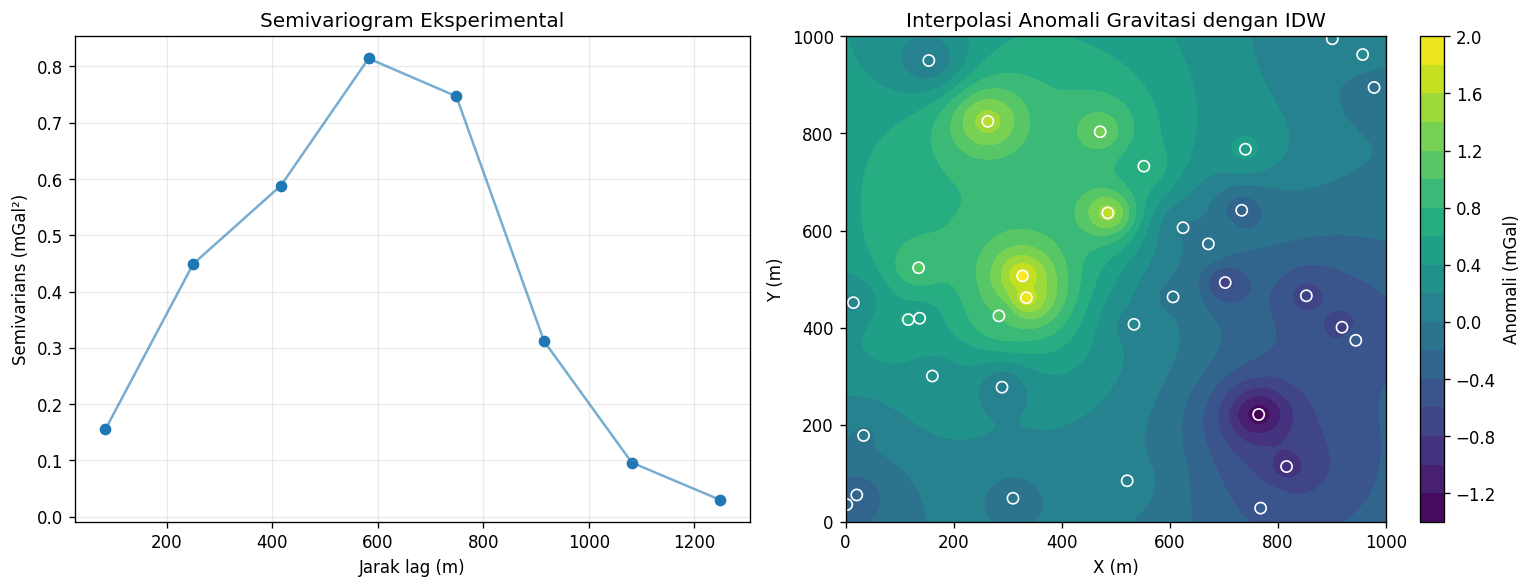

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data simulasi anomali gravitasi (bukan data lapangan)
np.random.seed(12)
n = 35
x = np.random.uniform(0, 1000, n)
y = np.random.uniform(0, 1000, n)
anomali = (
    2.5 * np.exp(-(((x-350)/220)**2 + ((y-650)/250)**2))
    - 1.8 * np.exp(-(((x-750)/180)**2 + ((y-300)/220)**2))
    + np.random.normal(0, 0.18, n)
)

data_geo = pd.DataFrame({"X_m": x, "Y_m": y, "Anomali_mGal": anomali})
display(data_geo.head())
print("Jumlah titik:", len(data_geo))
print(f"Rentang anomali: {anomali.min():.2f} sampai {anomali.max():.2f} mGal")

# Semivariogram eksperimental menggunakan pasangan titik
pasangan_h, pasangan_gamma = [], []
for i in range(n):
    for j in range(i+1, n):
        h = np.hypot(x[i]-x[j], y[i]-y[j])
        gamma = 0.5 * (anomali[i]-anomali[j])**2
        pasangan_h.append(h)
        pasangan_gamma.append(gamma)

pasangan_h = np.array(pasangan_h)
pasangan_gamma = np.array(pasangan_gamma)
batas_lag = np.linspace(0, pasangan_h.max(), 9)
lag_tengah, gamma_rata = [], []
for a, b in zip(batas_lag[:-1], batas_lag[1:]):
    mask = (pasangan_h >= a) & (pasangan_h < b)
    if mask.any():
        lag_tengah.append((a+b)/2)
        gamma_rata.append(pasangan_gamma[mask].mean())

# IDW untuk grid peta
gx, gy = np.meshgrid(np.linspace(0, 1000, 100), np.linspace(0, 1000, 100))
prediksi = np.zeros_like(gx)
for r in range(gx.shape[0]):
    for c in range(gx.shape[1]):
        d = np.hypot(x-gx[r,c], y-gy[r,c])
        d = np.maximum(d, 1e-6)
        w = 1 / d**2
        prediksi[r,c] = np.sum(w*anomali) / np.sum(w)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(lag_tengah, gamma_rata, color="tab:blue")
ax[0].plot(lag_tengah, gamma_rata, color="tab:blue", alpha=0.6)
ax[0].set(title="Semivariogram Eksperimental", xlabel="Jarak lag (m)", ylabel="Semivarians (mGal²)")
ax[0].grid(alpha=0.25)

im = ax[1].contourf(gx, gy, prediksi, levels=15, cmap="viridis")
ax[1].scatter(x, y, c=anomali, edgecolor="white", cmap="viridis", s=45)
fig.colorbar(im, ax=ax[1], label="Anomali (mGal)")
ax[1].set(title="Interpolasi Anomali Gravitasi dengan IDW", xlabel="X (m)", ylabel="Y (m)")
plt.tight_layout()
plt.show()

print(f"Rentang hasil IDW: {prediksi.min():.2f} sampai {prediksi.max():.2f} mGal")

## C. Pembahasan dan verifikasi
- Semivariogram menunjukkan bagaimana perbedaan nilai anomali berubah terhadap jarak antar titik. Bentuknya dipengaruhi sebaran data dan derau simulasi.
- Peta IDW menampilkan perkiraan pola spasial anomali. Area dengan nilai lebih tinggi atau rendah merupakan pola dari data simulasi, bukan bukti langsung keberadaan struktur geologi tertentu.
- **Verifikasi:** hasil IDW semestinya berada di antara nilai minimum dan maksimum data masukan karena merupakan kombinasi berbobot positif.
- **Keterbatasan:** IDW tidak memberikan model ketidakpastian dan tidak menggunakan struktur korelasi spasial seperti kriging.

# TOPIK 2 — SEISMOLOGI: DIAGRAM WADATI DAN RASIO \(V_p/V_s\)

## A. Konsep
Diagram Wadati menggunakan hubungan antara waktu tiba gelombang P (\(T_P\)) dan selisih waktu tiba S–P (\(T_S-T_P\)). Pada model sederhana, kemiringan garis regresi dapat digunakan untuk memperkirakan rasio \(V_p/V_s\). Ketepatan estimasi dipengaruhi picking fase, jumlah stasiun, dan asumsi kecepatan yang relatif seragam.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Bertindak sebagai pembimbing praktikum seismologi.
- **T:** Buat Diagram Wadati, lakukan regresi linear, dan estimasi \(V_p/V_s\) serta waktu asal.
- **C:** Data waktu tiba dari sejumlah stasiun untuk satu kejadian gempa.
- **I:** Waktu tiba P dan S dalam detik.
- **K:** Data simulasi; nyatakan asumsi dan jangan menganggap hasil sebagai parameter gempa nyata.
- **O:** Tabel \(T_P\), \(T_S\), \(T_S-T_P\), grafik regresi, dan hasil estimasi.
- **Q:** Pastikan \(T_S>T_P\) dan regresi dihitung dari data yang sama dengan grafik.
- **V:** Bandingkan nilai rasio hasil estimasi dengan nilai model simulasi yang ditetapkan.

Kemiringan regresi = 0.708
Estimasi Vp/Vs = 1.708
Waktu asal estimasi (pendekatan) = 4.922 s
Rasio model Vp/Vs = 1.714


<cell 2>:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


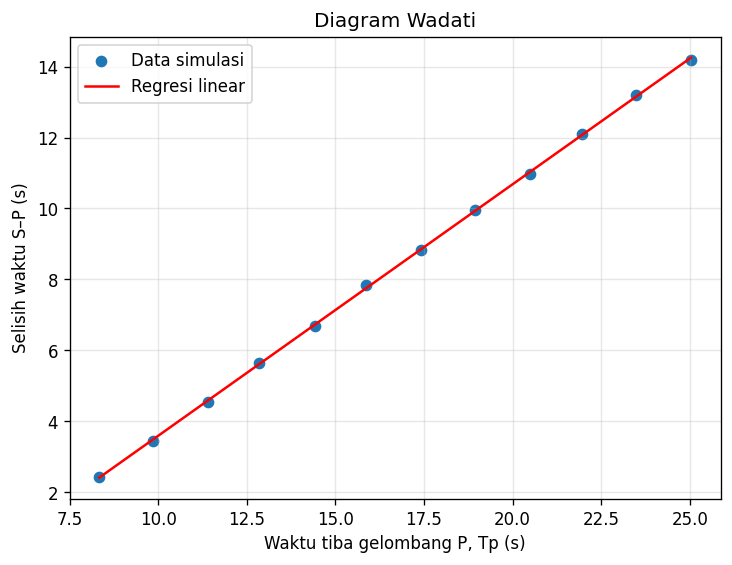

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(21)
n_stasiun = 12
# Data sintetis: waktu asal dan jarak menghasilkan waktu tiba P/S dengan sedikit noise
T0_model = 5.0
Vp_model, Vs_model = 6.0, 3.5  # km/s
jarak_km = np.linspace(20, 120, n_stasiun)
Tp = T0_model + jarak_km / Vp_model + np.random.normal(0, 0.025, n_stasiun)
Ts = T0_model + jarak_km / Vs_model + np.random.normal(0, 0.035, n_stasiun)
Tsp = Ts - Tp

# Regresi Tsp = m*Tp + b
m, b = np.polyfit(Tp, Tsp, 1)
rasio_vp_vs = 1 + m
T0_estimasi = np.mean(Tp - (Ts-Tp)/m)

tabel_wadati = pd.DataFrame({
    "Stasiun": [f"STA-{i+1:02d}" for i in range(n_stasiun)],
    "Tp_s": Tp, "Ts_s": Ts, "Ts_minus_Tp_s": Tsp
})
display(tabel_wadati.round(3))
print(f"Kemiringan regresi = {m:.3f}")
print(f"Estimasi Vp/Vs = {rasio_vp_vs:.3f}")
print(f"Waktu asal estimasi (pendekatan) = {T0_estimasi:.3f} s")
print(f"Rasio model Vp/Vs = {Vp_model/Vs_model:.3f}")

xreg = np.linspace(Tp.min(), Tp.max(), 100)
plt.figure(figsize=(7,5))
plt.scatter(Tp, Tsp, label="Data simulasi")
plt.plot(xreg, m*xreg+b, color="red", label="Regresi linear")
plt.xlabel("Waktu tiba gelombang P, Tp (s)")
plt.ylabel("Selisih waktu S–P (s)")
plt.title("Diagram Wadati")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## C. Pembahasan dan verifikasi
- Diagram menunjukkan hubungan antara \(T_P\) dan selisih waktu S–P. Regresi dipakai untuk memperoleh kemiringan yang selanjutnya digunakan mengestimasi rasio \(V_p/V_s\).
- Bandingkan rasio estimasi dengan rasio model. Selisih dapat timbul akibat derau yang sengaja ditambahkan ke waktu tiba.
- **Verifikasi:** semua nilai \(T_S-T_P\) harus positif dan grafik harus menggunakan variabel yang sama dengan perhitungan regresi.
- **Keterbatasan:** pendekatan ini mengasumsikan model kecepatan sederhana. Data nyata membutuhkan picking fase yang teliti dan evaluasi kualitas regresi.

# TOPIK 3 — METODE GRAVITASI: PEMISAHAN ANOMALI REGIONAL DAN RESIDUAL

## A. Konsep
Anomali gravitasi terukur dapat memuat komponen regional berpanjang gelombang besar dan residual yang lebih lokal. Pada latihan ini, komponen regional diperkirakan dengan bidang polinomial orde satu, lalu residual dihitung sebagai selisih antara anomali total dan hasil estimasi regional.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Bertindak sebagai analis metode gravitasi.
- **T:** Estimasi tren regional dan pisahkan anomali residual.
- **C:** Data gravitasi pada grid survei.
- **I:** Koordinat X–Y dan anomali Bouguer simulasi dalam mGal.
- **K:** Gunakan model regional sederhana dan jelaskan bahwa pemisahan bergantung pada pilihan model.
- **O:** Peta anomali total, regional, residual, serta statistik ringkas.
- **Q:** Pastikan residual = total − regional.
- **V:** Periksa bahwa residual memiliki rata-rata mendekati nol untuk model bidang dengan intersep.

Model regional: g = 10.103 + (0.00518)X + (-0.00328)Y
Rata-rata residual = 0.0000 mGal
Rentang residual = -1.95 hingga 2.48 mGal


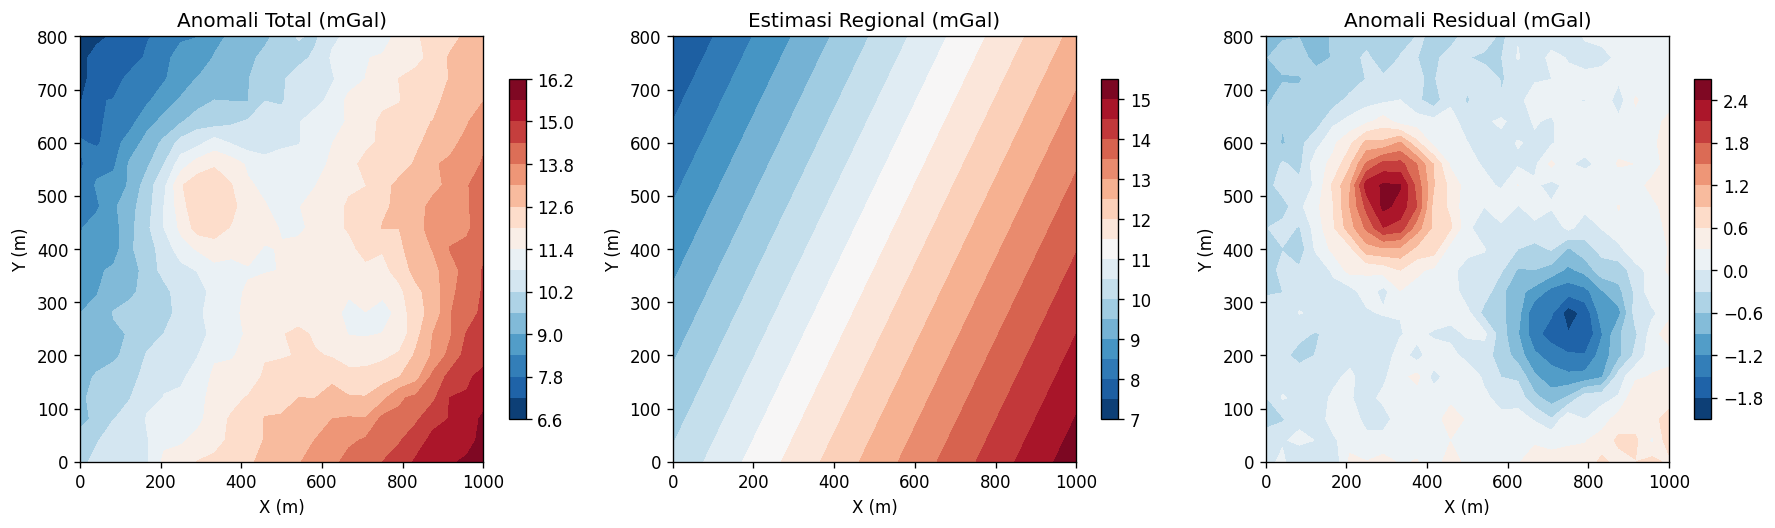

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(8)
xg = np.linspace(0, 1000, 25)
yg = np.linspace(0, 800, 21)
X, Y = np.meshgrid(xg, yg)
# Regional: tren bidang; residual: dua anomali lokal simulasi
regional_true = 10 + 0.006*X - 0.004*Y
residual_true = (
    2.8*np.exp(-(((X-300)/130)**2 + ((Y-500)/120)**2))
    - 2.2*np.exp(-(((X-750)/160)**2 + ((Y-250)/140)**2))
)
anomali_total = regional_true + residual_true + np.random.normal(0, 0.12, X.shape)

# Fit bidang regional: g = a + bX + cY
G = np.column_stack([np.ones(X.size), X.ravel(), Y.ravel()])
koef, *_ = np.linalg.lstsq(G, anomali_total.ravel(), rcond=None)
regional_estimasi = (G @ koef).reshape(X.shape)
residual = anomali_total - regional_estimasi

print(f"Model regional: g = {koef[0]:.3f} + ({koef[1]:.5f})X + ({koef[2]:.5f})Y")
print(f"Rata-rata residual = {residual.mean():.4f} mGal")
print(f"Rentang residual = {residual.min():.2f} hingga {residual.max():.2f} mGal")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
items = [
    (anomali_total, "Anomali Total (mGal)"),
    (regional_estimasi, "Estimasi Regional (mGal)"),
    (residual, "Anomali Residual (mGal)")
]
for a, (z, title) in zip(ax, items):
    c = a.contourf(X, Y, z, levels=15, cmap="RdBu_r")
    fig.colorbar(c, ax=a, shrink=0.8)
    a.set_title(title)
    a.set_xlabel("X (m)")
    a.set_ylabel("Y (m)")
plt.tight_layout()
plt.show()

## C. Pembahasan dan verifikasi
- Peta regional menggambarkan tren spasial berskala lebih besar yang ditangkap bidang polinomial.
- Peta residual menonjolkan variasi yang tidak dijelaskan oleh bidang regional. Pola tersebut pada data nyata dapat berkaitan dengan sumber dangkal atau efek lain, tetapi tidak dapat ditentukan dari peta saja.
- **Verifikasi:** residual dihitung sebagai anomali total dikurangi regional; rata-rata residual seharusnya relatif dekat nol karena model regional mengandung intersep.
- **Keterbatasan:** bidang orde satu mungkin terlalu sederhana untuk data lapangan dengan tren regional yang kompleks.

# TOPIK 4 — SEISMOLOGI: HUBUNGAN MAGNITUDO DAN JARAK (MODEL SEDERHANA)

## A. Konsep
Amplitudo gelombang yang tercatat umumnya dipengaruhi magnitudo sumber dan jarak ke stasiun. Untuk latihan ini digunakan hubungan empiris sintetis sederhana antara amplitudo, jarak, dan magnitudo. Persamaan ini hanya demonstrasi komputasi, **bukan rumus resmi untuk menghitung magnitudo lokal dari data observasi**.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Bertindak sebagai asisten seismologi komputasi.
- **T:** Evaluasi hubungan amplitudo terhadap jarak dan buat grafik atenuasi.
- **C:** Data simulasi amplitudo pada beberapa jarak stasiun.
- **I:** Jarak episentral dalam km dan amplitudo relatif.
- **K:** Beri label data simulasi; jangan menyatakan magnitudo hasil sebagai magnitudo gempa nyata.
- **O:** Tabel data, grafik amplitudo terhadap jarak, dan regresi log-amplitudo.
- **Q:** Gunakan logaritma hanya untuk amplitudo positif.
- **V:** Periksa tren umum penurunan amplitudo terhadap jarak.

Kemiringan regresi log-log = -1.501
R² regresi log-log = 0.922


<cell 4>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


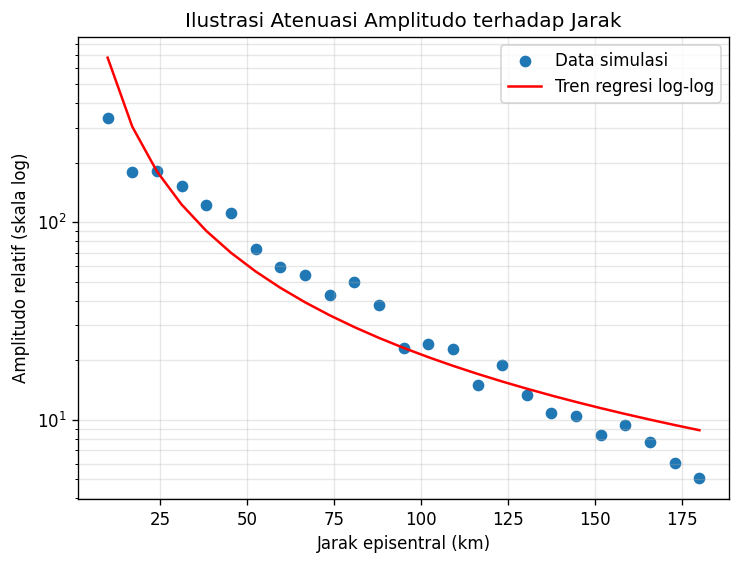

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(17)
jarak = np.linspace(10, 180, 25)
# Model sintetis amplitudo relatif menurun terhadap jarak
amplitudo = 1200 * np.exp(-jarak/65) / np.sqrt(jarak) 
amplitudo *= np.exp(np.random.normal(0, 0.12, len(jarak)))

log_amp = np.log10(amplitudo)
koef = np.polyfit(np.log10(jarak), log_amp, 1)
log_pred = np.polyval(koef, np.log10(jarak))
r2 = 1 - np.sum((log_amp-log_pred)**2) / np.sum((log_amp-log_amp.mean())**2)

df_amp = pd.DataFrame({"Jarak_km": jarak, "Amplitudo_rel": amplitudo})
display(df_amp.round(3))
print(f"Kemiringan regresi log-log = {koef[0]:.3f}")
print(f"R² regresi log-log = {r2:.3f}")

plt.figure(figsize=(7,5))
plt.scatter(jarak, amplitudo, label="Data simulasi")
plt.plot(jarak, 10**log_pred, color="red", label="Tren regresi log-log")
plt.yscale("log")
plt.xlabel("Jarak episentral (km)")
plt.ylabel("Amplitudo relatif (skala log)")
plt.title("Ilustrasi Atenuasi Amplitudo terhadap Jarak")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## C. Pembahasan dan verifikasi
- Amplitudo pada model simulasi cenderung menurun ketika jarak bertambah. Sebaran nilai menunjukkan adanya variasi acak.
- Regresi log-log merangkum tren hubungan jarak dan amplitudo, tetapi koefisiennya bukan parameter magnitudo baku.
- **Verifikasi:** amplitudo harus positif sebelum transformasi logaritma; \(R^2\) berada pada rentang 0–1 untuk regresi dengan intersep pada kasus ini.
- **Keterbatasan:** data nyata dipengaruhi instrumen, kondisi lintasan, atenuasi anelastik, geometri sumber, dan pemrosesan sinyal.

# TOPIK 5 — TEKTONOFISIKA: REGANGAN DARI DATA GPS

## A. Konsep
Data GPS dapat digunakan untuk memperkirakan deformasi kerak melalui perubahan posisi dari waktu ke waktu. Untuk dua komponen perpindahan horizontal, regangan sederhana dapat dihitung dari gradien kecepatan. Pada latihan ini dibuat medan kecepatan sintetis dan dihitung regangan normal serta geser menggunakan pendekatan beda hingga.

## B. Prompt AI (R–T–C–I–K–O–Q–V)
- **R:** Bertindak sebagai pembimbing tektonofisika.
- **T:** Hitung medan kecepatan GPS sintetis dan estimasi komponen regangan.
- **C:** Jaringan stasiun berada pada area datar lokal.
- **I:** Koordinat X–Y dalam km serta kecepatan Timur dan Utara dalam mm/tahun.
- **K:** Gunakan unit konsisten dan jelaskan bahwa hasil merupakan ilustrasi dari medan sintetis.
- **O:** Peta vektor kecepatan dan nilai regangan rata-rata.
- **Q:** Periksa unit gradien kecepatan per jarak.
- **V:** Bandingkan hasil hitungan dengan medan kecepatan yang diketahui dari model simulasi.

KOMPONEN LAJU REGANGAN (per tahun)
εxx = 3.000e-07 tahun⁻¹
εyy = 2.000e-07 tahun⁻¹
εxy = 5.000e-09 tahun⁻¹
Catatan: hasil adalah ilustrasi berdasarkan medan kecepatan simulasi.


<cell 5>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


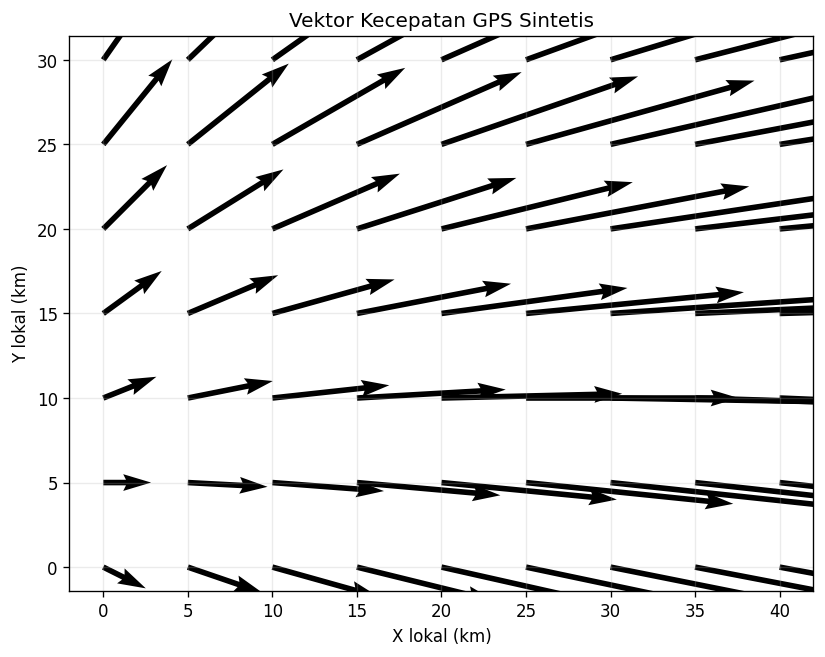

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Grid stasiun GPS sintetis (koordinat lokal km)
x = np.linspace(0, 40, 9)
y = np.linspace(0, 30, 7)
X, Y = np.meshgrid(x, y)

# Medan kecepatan sintetis (mm/tahun), dengan gradien sederhana
Ve = 2.0 + 0.30*X + 0.05*Y
Vn = -1.0 - 0.04*X + 0.20*Y

# Gradien kecepatan: (mm/tahun)/km
dVe_dy, dVe_dx = np.gradient(Ve, y, x)
dVn_dy, dVn_dx = np.gradient(Vn, y, x)

# Komponen regangan laju dalam satuan per tahun (konversi km ke mm)
exx = dVe_dx / 1_000_000
eyy = dVn_dy / 1_000_000
exy = 0.5*(dVe_dy + dVn_dx) / 1_000_000

print("KOMPONEN LAJU REGANGAN (per tahun)")
print(f"εxx = {np.mean(exx):.3e} tahun⁻¹")
print(f"εyy = {np.mean(eyy):.3e} tahun⁻¹")
print(f"εxy = {np.mean(exy):.3e} tahun⁻¹")
print("Catatan: hasil adalah ilustrasi berdasarkan medan kecepatan simulasi.")

plt.figure(figsize=(8,6))
plt.quiver(X, Y, Ve, Vn, scale=35)
plt.xlabel("X lokal (km)")
plt.ylabel("Y lokal (km)")
plt.title("Vektor Kecepatan GPS Sintetis")
plt.grid(alpha=0.25)
plt.axis("equal")
plt.show()

## C. Pembahasan dan verifikasi
- Panjang panah menunjukkan besar relatif kecepatan, sedangkan arah panah menunjukkan arah gerak pada sistem koordinat lokal.
- Regangan normal menggambarkan perubahan relatif panjang pada arah X dan Y; regangan geser merepresentasikan perubahan sudut.
- **Verifikasi:** komponen regangan harus dihitung dari gradien kecepatan dengan konversi satuan yang konsisten.
- **Keterbatasan:** interpretasi tektonik pada data nyata memerlukan koreksi kerangka referensi, ketidakpastian posisi/kecepatan, dan jaringan stasiun yang memadai.

# KESIMPULAN UMUM

Lima contoh ini menunjukkan bahwa AI dapat membantu merancang alur analisis geofisika, menyiapkan kode Python, membuat visualisasi, dan menyusun interpretasi awal. Namun, keluaran AI tetap perlu diverifikasi melalui pemeriksaan satuan, persamaan, asumsi model, dan kesesuaian grafik dengan perhitungan.

note: data yang saya gunakan adalah data simulasi saja, bukan data sebenarnya
